In [9]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/raw_csv_itbi.csv",
    sep=";",
    decimal=",",
    encoding="utf-8"
)

df.head()

,logradouro,numero,complemento,valor_avaliacao,bairro,cidade,uf,ano_construcao,area_terreno,area_construida,...,tipo_construcao,tipo_ocupacao,data_transacao,estado_conservacao,tipo_imovel,sfh,cod_logradouro,latitude,longitude,ano
0,av norte miguel arraes de alencar,3071,NaN,1068562.63,Encruzilhada,Recife,PE,1997,438.00,511.00,...,Galpão,COMERCIAL SEM LIXO ORGANICO,2025-11-30,Regular,Galpão,0.0,46540,-8.034273,-34.896337,2025
1,av norte miguel arraes de alencar,3071,NaN,1068562.63,Encruzilhada,Recife,PE,1997,438.00,511.00,...,Galpão,COMERCIAL SEM LIXO ORGANICO,2025-11-30,Regular,Galpão,0.0,46540,-8.034273,-34.896337,2025
2,av norte miguel arraes de alencar,3029,NaN,1951000.00,Encruzilhada,Recife,PE,1957,779.33,582.44,...,Casa,COMERCIAL SEM LIXO ORGANICO,2025-11-30,Regular,Casa,0.0,46540,-8.034435,-34.896335,2025
3,rua caio pereira,375,apto 101 edf luar do rosarinho,393452.82,Encruzilhada,Recife,PE,2007,798.91,118.64,...,Apartamento > 4 Pavimentos,RESIDENCIAL,2025-11-28,Bom,Apartamento,263000.0,13269,-8.034996,-34.896187,2025
4,rua caio pereira,375,apto 501 edf luar do rosarinho,402821.74,Encruzilhada,Recife,PE,2007,798.91,118.64,...,Apartamento > 4 Pavimentos,RESIDENCIAL,2025-10-02,Bom,Apartamento,200000.0,13269,-8.034996,-34.896187,2025


In [10]:
categoricas = [
    "bairro",
    "padrao_acabamento",
    "tipo_construcao",
    "tipo_ocupacao",
    "estado_conservacao",
    "tipo_imovel",
    "cidade",
    "uf"
]

cardinalidade = (
    df[categoricas]
    .nunique(dropna=True)
    .to_frame(name="cardinalidade")
    .sort_values("cardinalidade", ascending=False)
)

display(cardinalidade)

,cardinalidade
bairro,87
tipo_imovel,18
tipo_construcao,16
padrao_acabamento,3
tipo_ocupacao,3
estado_conservacao,3
cidade,1
uf,1


In [11]:
for coluna in categoricas:
    frequencia = df[coluna].value_counts(dropna=False)

    tabela = pd.DataFrame({
        "quantidade": frequencia,
        "percentual": (frequencia / len(df) * 100).round(2)
    })

    print(f"\nColuna: {coluna}")
    display(tabela)


Coluna: bairro


,quantidade,percentual
bairro,,
Boa Viagem,4340,26.60
Varzea,1101,6.75
Imbiribeira,885,5.42
Boa Vista,699,4.28
Madalena,582,3.57
...,...,...
Mustardinha,2,0.01
Jiquia,2,0.01
Toto,2,0.01



Coluna: padrao_acabamento


,quantidade,percentual
padrao_acabamento,,
Superior,9557,58.57
Médio,4700,28.80
Simples,2061,12.63



Coluna: tipo_construcao


...

,quantidade,percentual
tipo_imovel,,
Apartamento,13341,81.76
Casa,1185,7.26
Sala,1177,7.21
Loja,221,1.35
Edificação Especial,127,0.78
Centro Comercial/Serviços,72,0.44
Galpão,70,0.43
Hotel,34,0.21
Instituição Financeira,23,0.14



Coluna: cidade


,quantidade,percentual
cidade,,
Recife,16318,100.0



Coluna: uf


,quantidade,percentual
uf,,
PE,16318,100.0


In [19]:
import unicodedata

def normalizar_texto(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(
        caractere for caractere in texto
        if not unicodedata.combining(caractere)
    )
    return " ".join(texto.casefold().split())

for coluna in categoricas:
    valores = pd.DataFrame({
        "original": df[coluna].dropna().unique()
    })

    valores["normalizado"] = valores["original"].map(normalizar_texto)

    variantes = (
        valores.groupby("normalizado")["original"]
        .agg(list)
    )

    variantes = variantes[variantes.map(len) > 1]

    print(f"\nPossíveis grafias duplicadas em {coluna}:")
    display(variantes.to_frame("grafias"))

    texto = df[coluna].astype("string")
    espacos = texto.str.contains(r"^\s|\s$|\s{2,}", na=False)

    print("Valores com espaços extras:")
    display(df.loc[espacos, coluna].value_counts())


Possíveis grafias duplicadas em bairro:


,grafias
normalizado,
gracas,"[Gracas, Graças]"
santo antonio,"[Santo Antonio, Santo Antônio]"
sao jose,"[Sao Jose, São José]"


Valores com espaços extras:


bairro
Cohab   Ibura    28
Name: count, dtype: int64


Possíveis grafias duplicadas em padrao_acabamento:


...

Series([], Name: count, dtype: int64)


Possíveis grafias duplicadas em uf:


,grafias
normalizado,


Valores com espaços extras:


Series([], Name: count, dtype: int64)

In [14]:
eda = df.copy()

for coluna in categoricas:
    eda[coluna] = (
        eda[coluna].astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

eda["bairro"] = eda["bairro"].replace({
    "Gracas": "Graças",
    "Santo Antonio": "Santo Antônio",
    "Sao Jose": "São José"
})

display(pd.DataFrame({
    "cardinalidade_original": df[categoricas].nunique(),
    "cardinalidade_padronizada": eda[categoricas].nunique()
}))

,cardinalidade_original,cardinalidade_padronizada
bairro,87,84
padrao_acabamento,3,3
tipo_construcao,16,16
tipo_ocupacao,3,3
estado_conservacao,3,3
tipo_imovel,18,18
cidade,1,1
uf,1,1


In [15]:
base_faltantes = df.replace(r"^\s*$", pd.NA, regex=True)

faltantes = pd.DataFrame({
    "quantidade faltante": base_faltantes.isna().sum(),
    "percentual faltante": base_faltantes.isna().mean().mul(100)
}).sort_values("percentual faltante", ascending=False)

display(faltantes.round(2))

,quantidade faltante,percentual faltante
longitude,5850,35.85
latitude,5850,35.85
complemento,1380,8.46
valor_avaliacao,0,0.00
numero,0,0.00
logradouro,0,0.00
cidade,0,0.00
bairro,0,0.00
uf,0,0.00
ano_construcao,0,0.00


In [16]:
categoricas_analise = [
    "bairro",
    "padrao_acabamento",
    "tipo_construcao",
    "tipo_ocupacao",
    "estado_conservacao",
    "tipo_imovel"
]

for coluna in categoricas_analise:
    resumo = (
        eda.groupby(coluna)["valor_avaliacao"]
        .agg(
            quantidade="count",
            mediana="median",
            q10=lambda valores: valores.quantile(0.10),
            q25=lambda valores: valores.quantile(0.25),
            q75=lambda valores: valores.quantile(0.75),
            q90=lambda valores: valores.quantile(0.90)
        )
        .sort_values("quantidade", ascending=False)
    )

    print(f"\nValor de avaliação por {coluna}:")
    display(resumo.round(2))


Valor de avaliação por bairro:


,quantidade,mediana,q10,q25,q75,q90
bairro,,,,,,
Boa Viagem,4340,461421.90,215151.95,307538.44,800000.00,1450000.00
Varzea,1101,257000.00,220000.00,250000.00,257000.00,335000.00
Imbiribeira,885,333000.00,219400.00,241968.51,395000.00,870000.00
Boa Vista,699,311547.16,70000.00,160000.00,425667.26,549871.77
Madalena,582,440000.00,240000.00,344075.69,800000.00,1125885.38
...,...,...,...,...,...,...
Jiquia,2,2337500.00,687500.00,1306250.00,3368750.00,3987500.00
Mustardinha,2,260000.00,164000.00,200000.00,320000.00,356000.00
Corrego Do Jenipapo,2,235000.00,159000.00,187500.00,282500.00,311000.00



Valor de avaliação por padrao_acabamento:


,quantidade,mediana,q10,q25,q75,q90
padrao_acabamento,,,,,,
Superior,9557,380000.0,217003.49,255000.0,650000.0,1225000.0
Médio,4700,350000.0,165000.00,250000.0,480000.0,800000.0
Simples,2061,250000.0,120000.00,170000.0,426379.0,800000.0



Valor de avaliação por tipo_construcao:


...

,quantidade,mediana,q10,q25,q75,q90
tipo_ocupacao,,,,,,
RESIDENCIAL,14261,348000.0,195000.0,245000.0,550000.00,975387.26
COMERCIAL SEM LIXO ORGANICO,1045,367734.5,90000.0,170000.0,782587.61,1207798.56
COMERCIAL COM LIXO ORGANICO,1012,425806.0,130100.0,230000.0,1100000.00,3899000.00



Valor de avaliação por estado_conservacao:


,quantidade,mediana,q10,q25,q75,q90
estado_conservacao,,,,,,
Bom,16118,350000.00,181974.34,243750.66,570000.0,1075000.00
Regular,191,261122.94,140000.00,177500.00,670838.5,1868251.63
Mau,9,600000.00,326000.00,350000.00,811834.7,1593259.80



Valor de avaliação por tipo_imovel:


,quantidade,mediana,q10,q25,q75,q90
tipo_imovel,,,,,,
Apartamento,13341,342000.00,199000.00,245000.00,531070.34,913813.62
Casa,1185,470000.00,175479.50,280000.00,900000.00,1767760.48
Sala,1177,253521.99,100000.00,150000.00,468750.00,809528.87
Loja,221,566970.63,135000.00,254904.75,1746000.00,4958000.00
Edificação Especial,127,1646428.00,620000.00,1090000.00,4050000.00,10235340.00
Centro Comercial/Serviços,72,412820.07,240000.00,350800.88,525000.00,790000.00
Galpão,70,2152045.50,560800.00,925875.00,7500000.00,18985909.00
Hotel,34,427032.12,223339.37,302500.00,514234.79,857143.27
Instituição Financeira,23,751704.06,25000.00,26000.00,6931486.50,8349227.50


In [18]:
print("Só testando kernell")

Só testando kernell


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Identifica nulos e textos vazios.
faltantes = eda.isna()

for coluna in eda.select_dtypes(include=["object", "string"]).columns:
    vazios = eda[coluna].astype("string").str.strip().eq("")
    faltantes[coluna] = faltantes[coluna] | vazios.fillna(False)

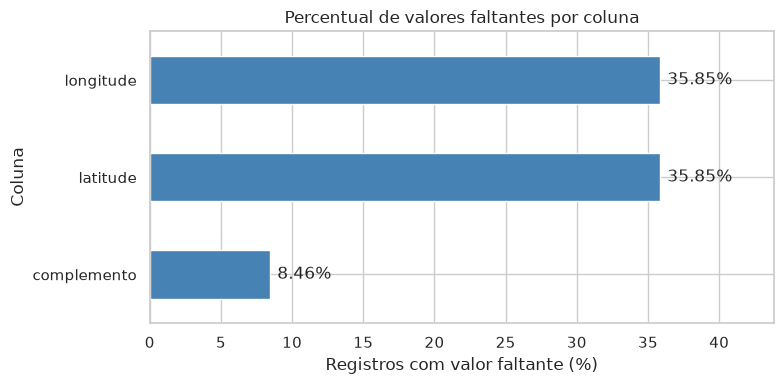

In [23]:
percentuais = (
    faltantes.mean().mul(100)
    .loc[lambda s: s > 0]
    .sort_values()
)

ax = percentuais.plot.barh(figsize=(8, 4), color="steelblue")

for i, valor in enumerate(percentuais):
    ax.text(valor + 0.5, i, f"{valor:.2f}%", va="center")

ax.set_xlim(0, percentuais.max() + 8)
ax.set_title("Percentual de valores faltantes por coluna")
ax.set_xlabel("Registros com valor faltante (%)")
ax.set_ylabel("Coluna")

plt.tight_layout()
plt.show()

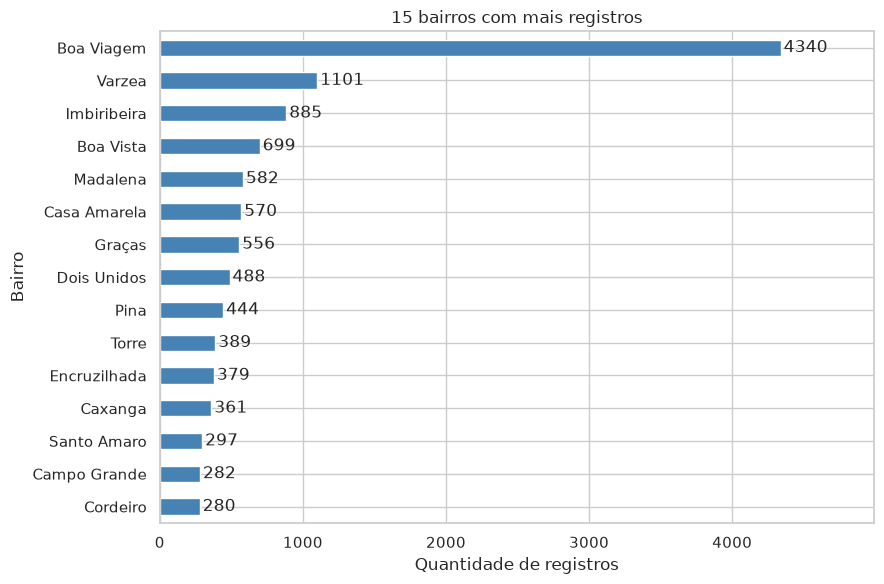

In [24]:
contagens = (
    eda["bairro"].value_counts()
    .head(15)
    .sort_values()
)

ax = contagens.plot.barh(figsize=(9, 6), color="steelblue")

for i, valor in enumerate(contagens):
    ax.text(valor + 20, i, str(valor), va="center")

ax.set_xlim(0, contagens.max() * 1.15)
ax.set_title("15 bairros com mais registros")
ax.set_xlabel("Quantidade de registros")
ax.set_ylabel("Bairro")

plt.tight_layout()
plt.show()

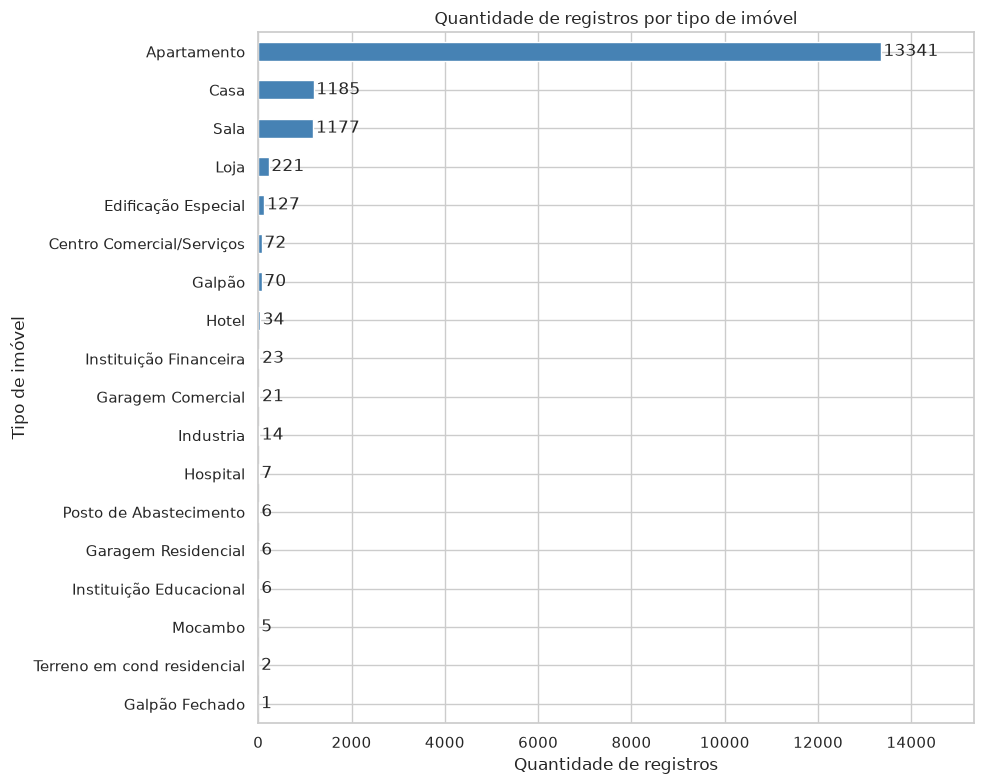

In [25]:
contagens = eda["tipo_imovel"].value_counts().sort_values()

ax = contagens.plot.barh(figsize=(10, 8), color="steelblue")

for i, valor in enumerate(contagens):
    ax.text(valor + 60, i, str(valor), va="center")

ax.set_xlim(0, contagens.max() * 1.15)
ax.set_title("Quantidade de registros por tipo de imóvel")
ax.set_xlabel("Quantidade de registros")
ax.set_ylabel("Tipo de imóvel")

plt.tight_layout()
plt.show()

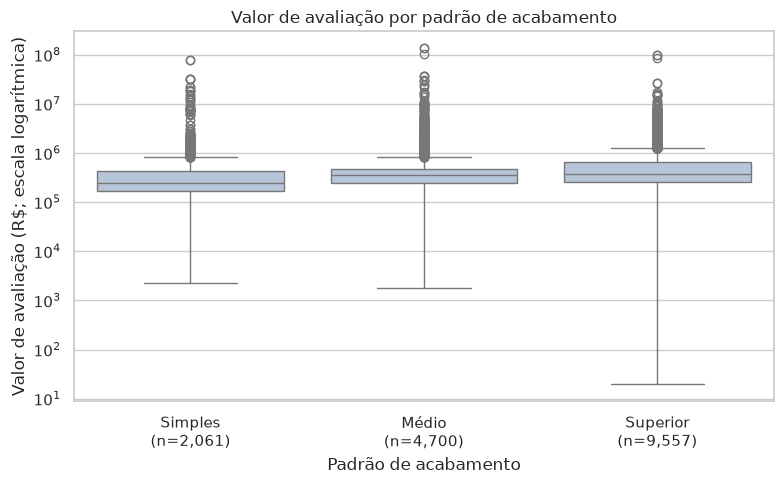

In [26]:
dados = eda.loc[eda["valor_avaliacao"] > 0].copy()
ordem = ["Simples", "Médio", "Superior"]

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=dados,
    x="padrao_acabamento",
    y="valor_avaliacao",
    order=ordem,
    color="lightsteelblue",
    ax=ax
)

contagens = dados["padrao_acabamento"].value_counts()

ax.set_xticks(range(len(ordem)))
ax.set_xticklabels([
    f"{categoria}\n(n={contagens.get(categoria, 0):,})"
    for categoria in ordem
])

ax.set_yscale("log")
ax.set_title("Valor de avaliação por padrão de acabamento")
ax.set_xlabel("Padrão de acabamento")
ax.set_ylabel("Valor de avaliação (R$; escala logarítmica)")

plt.tight_layout()
plt.show()

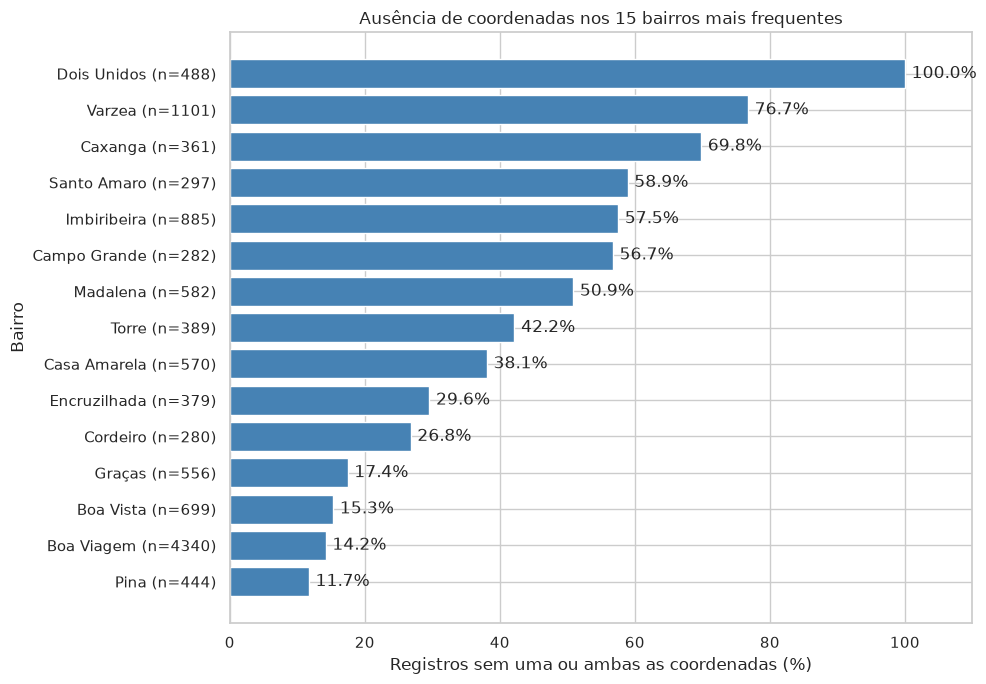

In [27]:
geo = eda[["bairro"]].copy()

geo["sem_coordenadas"] = faltantes[
    ["latitude", "longitude"]
].any(axis=1)

resumo_geo = (
    geo.groupby("bairro")
    .agg(
        n=("sem_coordenadas", "size"),
        faltantes_pct=("sem_coordenadas", lambda s: s.mean() * 100)
    )
)

bairros_top = eda["bairro"].value_counts().head(15).index

dados = (
    resumo_geo.loc[bairros_top]
    .sort_values("faltantes_pct")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    range(len(dados)),
    dados["faltantes_pct"],
    color="steelblue"
)

ax.set_yticks(range(len(dados)))
ax.set_yticklabels([
    f"{bairro} (n={int(n)})"
    for bairro, n in zip(dados.index, dados["n"])
])

for i, valor in enumerate(dados["faltantes_pct"]):
    ax.text(valor + 1, i, f"{valor:.1f}%", va="center")

ax.set_xlim(0, 110)
ax.set_title("Ausência de coordenadas nos 15 bairros mais frequentes")
ax.set_xlabel("Registros sem uma ou ambas as coordenadas (%)")
ax.set_ylabel("Bairro")

plt.tight_layout()
plt.show()